# JS09 - Praktikum 2: Klasifikasi Naive Bayes dengan Data Dummy
**Mata Kuliah:** Pembelajaran Mesin  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi
Membuat data sintetis dengan `make_classification`, diskritisasi nilai numerik, visualisasi sebaran data, dan komparasi performa `MultinomialNB` vs `GaussianNB`.


   Fitur 1  Fitur 2  Label    Kelas
0      112      139      0  Kelas B
1      179      210      0  Kelas B
2       83       71      0  Kelas B
3      182      265      0  Kelas B
4      105       78      0  Kelas B
Multinomial NB -> Train: 0.8095 | Test: 0.3333
Gaussian NB    -> Train: 0.8571 | Test: 0.4444


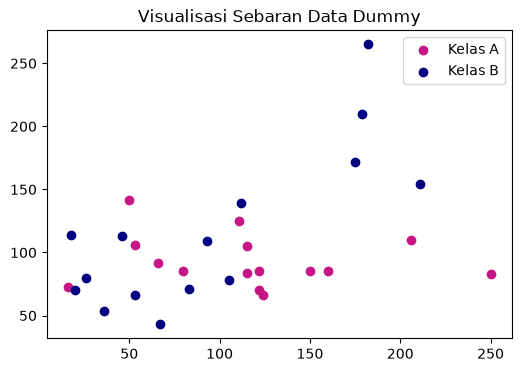

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.metrics import accuracy_score

# 1. Buat data dummy
X, y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, shuffle=False, random_state=42)
X = np.round(np.absolute(X), 2) * 100
X = X.astype(int)

df = pd.DataFrame(X, columns=['Fitur 1', 'Fitur 2'])
df['Label'] = y
df['Kelas'] = df['Label'].map({1: 'Kelas A', 0: 'Kelas B'})
display(df.head())

# 2. Visualisasi
plt.figure(figsize=(6, 4))
plt.scatter(df[df['Label']==1]['Fitur 1'], df[df['Label']==1]['Fitur 2'], color='mediumvioletred', label='Kelas A')
plt.scatter(df[df['Label']==0]['Fitur 1'], df[df['Label']==0]['Fitur 2'], color='navy', label='Kelas B')
plt.title("Visualisasi Sebaran Data Dummy")
plt.legend()
plt.show()

# 3. Model Multinomial & Gaussian
X_tr, X_ts, y_tr, y_ts = train_test_split(X, y, test_size=0.3, random_state=30)

mnb = MultinomialNB().fit(X_tr, y_tr)
gnb = GaussianNB().fit(X_tr, y_tr)

print(f"Multinomial NB -> Train: {accuracy_score(y_tr, mnb.predict(X_tr)):.4f} | Test: {accuracy_score(y_ts, mnb.predict(X_ts)):.4f}")
print(f"Gaussian NB    -> Train: {accuracy_score(y_tr, gnb.predict(X_tr)):.4f} | Test: {accuracy_score(y_ts, gnb.predict(X_ts)):.4f}")
